<a href="https://colab.research.google.com/github/saulobortolon/Quaternios-Kalman-CC/blob/main/dominios/notebooks/X3d_duais_perseguicao.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Abrir no Colab"/></a>

# Domínio III (d): Pepé no mastro, Penélope na parede do silo

## Um estado que dá a volta: o ⊟ na inovação e no controle, e jacobianos por números duais

**Série:** [raiz](X0_raiz.ipynb) ([Colab](https://colab.research.google.com/github/saulobortolon/Quaternios-Kalman-CC/blob/main/dominios/notebooks/X0_raiz.ipynb)) · **Domínio:** [nó 3](X3_duais.ipynb) ([Colab](https://colab.research.google.com/github/saulobortolon/Quaternios-Kalman-CC/blob/main/dominios/notebooks/X3_duais.ipynb)) · **Anterior:** [X3c_duais_edo.ipynb](X3c_duais_edo.ipynb) ([Colab](https://colab.research.google.com/github/saulobortolon/Quaternios-Kalman-CC/blob/main/dominios/notebooks/X3c_duais_edo.ipynb))

**A história.** Penélope anda pela parede interna de um **silo cilíndrico** de 5 m de raio e 10 m de altura. Pepé está agarrado ao **mastro** que passa pelo centro do silo, como num poste de bombeiro: ele só pode **girar** em volta do mastro e **subir ou descer** por ele. São exatamente os dois movimentos do domínio III, o giro e o deslizamento no mesmo eixo. Pepé quer ficar de frente para Penélope e na mesma altura que ela.

O estado de Penélope também é um ponto do cilindro: o ângulo $\varphi$ e a altura $z$. E o ângulo **dá a volta**: depois de $\pi$ vem $-\pi$. Este notebook mostra o que acontece quando um filtro de Kalman, ou o controle de Pepé, esquece disso.

**O que este notebook mostra.**
1. Com uma câmera no teto do silo, que mede o ângulo de Penélope **enrolado** em $(-\pi,\pi]$, o filtro de Kalman precisa calcular a inovação com $\boxminus$. Sem isso, cada vez que Penélope passa por $\pm180°$, a estimativa dá uma volta inteira para o lado errado.
2. Se a estimativa do ângulo é guardada enrolada, o **controle** de Pepé também precisa do $\boxminus$. Sem ele, Pepé gira pelo caminho mais longo, e passa boa parte do tempo de costas para ela.
3. Os **olhos** de Pepé são uma câmera presa a ele, com campo de visão limitado. A medida é não linear (uma tangente), e o jacobiano do EKF sai por **números duais**, sem derivar nada à mão. Os olhos são muito mais precisos que a câmera do teto, mas só funcionam enquanto ela está à vista.

**Roteiro**
1. O mundo: o silo, Penélope e Pepé
2. Os sensores: a câmera do teto e os olhos de Pepé
3. A câmera do teto e o $\boxminus$ na inovação
4. O $\boxminus$ no controle
5. Os olhos de Pepé: EKF com jacobianos por números duais
6. Tudo junto
7. O que levar deste notebook
8. Exercícios

In [1]:
# Ferramentas comuns da série (repetidas em todos os notebooks, para que cada um rode sozinho no Colab)
import numpy as np
import matplotlib.pyplot as plt

np.set_printoptions(precision=6, suppress=True)
plt.rcParams.update({"axes.grid": True, "grid.alpha": 0.3, "figure.dpi": 100,
                     "axes.spines.top": False, "axes.spines.right": False})

def confere(nome, obtido, esperado, tol=1e-9, relativo=False):
    """Compara duas quantidades. Imprime OK ou interrompe o notebook com uma mensagem clara."""
    a, b = np.asarray(obtido), np.asarray(esperado)
    tipo = complex if (np.iscomplexobj(a) or np.iscomplexobj(b)) else float      # aceita complexos (domínio IV)
    a, b = a.astype(tipo), b.astype(tipo)
    escala = max(np.max(np.abs(b)), 1e-300) if relativo else 1.0
    erro = float(np.max(np.abs(a - b)) / escala)
    ok = erro <= tol
    print(f"{'OK ' if ok else 'FALHOU'}  {nome}:  diferença {'relativa ' if relativo else ''}máxima = {erro:.2e}")
    assert ok, f"conferência falhou: {nome}"

import pandas as pd
from scipy.linalg import expm
N_MC = 20            # simulações de Monte Carlo por configuração (20 → ~15 s no total)

class Dual:
    """Número dual re + ε·du (notebook III(a))."""
    __array_priority__ = 1000
    def __init__(self, re, du=0.0): self.re, self.du = re, du
    @staticmethod
    def _d(o): return o if isinstance(o, Dual) else Dual(o, 0.0)
    def __add__(self, o): o = Dual._d(o); return Dual(self.re + o.re, self.du + o.du)
    __radd__ = __add__
    def __neg__(self): return Dual(-self.re, -self.du)
    def __sub__(self, o): return self + (-Dual._d(o))
    def __rsub__(self, o): return Dual._d(o) - self
    def __mul__(self, o): o = Dual._d(o); return Dual(self.re * o.re, self.re * o.du + self.du * o.re)
    __rmul__ = __mul__
    def __truediv__(self, o): o = Dual._d(o); return Dual(self.re / o.re, (self.du * o.re - self.re * o.du) / o.re**2)
    def __rtruediv__(self, o): return Dual._d(o) / self

def _eleva(f, df):
    return lambda x: Dual(f(x.re), df(x.re) * x.du) if isinstance(x, Dual) else f(x)
tan = _eleva(np.tan, lambda a: 1 / np.cos(a)**2)
cos = _eleva(np.cos, lambda a: -np.sin(a))

def jacobiano_dual(h, x, *args):
    """Jacobiano de h em x, uma passada de duais por coluna (notebook III(b))."""
    cols = []
    for j in range(len(x)):
        xd = [Dual(x[i], 1.0 if i == j else 0.0) for i in range(len(x))]
        cols.append([y.du if isinstance(y, Dual) else 0.0 for y in h(xd, *args)])
    return np.array(cols).T

def wrap(a):
    """Enrola para (−π, π] (notebook III(a)): é o ⊟ do círculo quando aplicado a uma diferença."""
    return np.pi - (np.pi - np.asarray(a, float)) % (2 * np.pi)

---

## 1. O mundo

**O silo** tem raio $R=5$ m e altura $H=10$ m. Penélope está na parede, no ângulo $\varphi$ e na altura $z$.

**Penélope** se move como nos domínios anteriores, agora sobre a parede: massa de 1 kg, atrito viscoso de 1 N·s/m, e três forças:
- uma **força aleatória** suave (Ornstein–Uhlenbeck, constante de tempo de 1,5 s, desvio de 2 N), independente na direção horizontal (ao longo da parede) e na vertical;
- uma **força de fuga** horizontal de até 3 N quando Pepé está olhando para ela de perto: quando a diferença de ângulo é menor que 0,5 rad (29°) e a de altura é menor que 2 m. Ela não gosta de ser encarada;
- o **chão e o teto**, molas duras que só agem se ela tentar atravessá-los.

Na horizontal, uma força $F$ ao longo da parede dá aceleração angular $F/(mR)$. A integração usa a discretização exata do notebook I(c), com o estado $(\varphi,z,\dot\varphi,\dot z)$; o ângulo de Penélope é guardado **sem enrolar** (a verdade não precisa de cuidado), e é enrolado só quando um sensor o mede.

**Pepé** gira em volta do mastro com velocidade angular proporcional ao ângulo que falta para ficar de frente para a estimativa, limitada a 0,5 rad/s (que, na parede, equivale a 2,5 m/s, a velocidade máxima de Pepé nos domínios anteriores). Na vertical, sobe ou desce com velocidade proporcional à diferença de altura, limitada a 1,5 m/s.

Penélope começa em $\varphi=3{,}0$ rad (172°), perto de $\pm180°$, a meia altura. Pepé começa virado para $\theta=2{,}0$ rad, também a meia altura.

In [2]:
DT, T_FIM = 0.05, 60.0
R, H = 5.0, 10.0
SIG_F, TAU_F = 2.0, 1.5
F_FUGA, ANG_FUGA, Z_FUGA = 3.0, 0.5, 2.0
K_PAREDE = 50.0
W_MAX, VZ_MAX, GANHO = 0.5, 1.5, 1.5
INICIO_A, INICIO_P = np.array([3.0, 5.0]), np.array([2.0, 5.0])

def discretiza(A, B, dt, q=None):
    """F, G (e Q, se q for dado: intensidades por entrada), exatos (notebook III(c))."""
    n, m = A.shape[0], B.shape[1]
    Maug = np.zeros((n + m, n + m)); Maug[:n, :n] = A; Maug[:n, n:] = B
    E = expm(Maug * dt); F, G = E[:n, :n], E[:n, n:]
    if q is None:
        return F, G
    V = np.zeros((2 * n, 2 * n)); V[:n, :n] = -A; V[:n, n:] = B @ np.diag(q) @ B.T; V[n:, n:] = A.T
    W = expm(V * dt); Q = F @ W[:n, n:]
    return F, G, 0.5 * (Q + Q.T)

A_cv = np.zeros((4, 4)); A_cv[0, 2] = A_cv[1, 3] = 1.0
B_cv = np.zeros((4, 2)); B_cv[2, 0] = B_cv[3, 1] = 1.0
A_pen = A_cv.copy(); A_pen[2, 2] = A_pen[3, 3] = -1.0            # atrito viscoso (por unidade de massa)
F_PEN, G_PEN = discretiza(A_pen, B_cv, DT)

def passo_mundo(ya, pp, f_al, rng):
    """ya = (φ, z, φ', z') de Penélope; pp = (θ, d) de Pepé."""
    f_al = f_al - f_al / TAU_F * DT + SIG_F * np.sqrt(2 * DT / TAU_F) * rng.standard_normal(2)
    dang = wrap(ya[0] - pp[0])
    encarada = abs(dang) < ANG_FUGA and abs(ya[1] - pp[1]) < Z_FUGA
    fuga = F_FUGA * np.sign(dang) * (1 - abs(dang) / ANG_FUGA) if encarada else 0.0
    paredes = -K_PAREDE * min(ya[1], 0.0) - K_PAREDE * max(ya[1] - H, 0.0)
    acel = np.array([(f_al[0] + fuga) / R, f_al[1] + paredes])        # angular (rad/s²) e vertical (m/s²)
    return F_PEN @ ya + G_PEN @ acel, f_al

def passo_pepe(pp, alvo, controle_com_menos=True):
    erro_ang = alvo[0] - pp[0]
    if controle_com_menos:
        erro_ang = wrap(erro_ang)                    # o caminho mais curto: ⊟
    th = pp[0] + np.clip(GANHO * erro_ang, -W_MAX, W_MAX) * DT
    d = np.clip(pp[1] + np.clip(GANHO * (alvo[1] - pp[1]), -VZ_MAX, VZ_MAX) * DT, 0.0, H)
    return np.array([th, d])

---

## 2. Os sensores

Os dois sensores medem a 10 Hz.

**A câmera do teto** vê o silo de cima e mede o ângulo e a altura de Penélope:
$$\mathbf z=\big(\mathrm{wrap}(\varphi+v_\varphi),\ z+v_z\big),\qquad\sigma_\varphi=0{,}05\text{ rad }(2{,}9°,\ 25\text{ cm na parede}),\quad\sigma_z=0{,}25\text{ m}.$$
O ângulo vem **enrolado** em $(-\pi,\pi]$, como todo sensor de ângulo de verdade (um `atan2` dentro do sensor). A medida é linear, exceto pelo enrolamento.

**Os olhos de Pepé** são uma câmera presa a ele, olhando na direção $\theta$ em que ele está virado, na altura $d$. Uma câmera do tipo *pinhole* com distância focal unitária vê um ponto à frente e de lado em coordenadas de imagem que são razões entre distâncias. Para Penélope na parede, com $\Delta=\varphi\boxminus\theta$ a diferença de ângulo:
$$u=\tan\Delta,\qquad w=\frac{z-d}{R\cos\Delta},\qquad\text{com ruído de }0{,}005\text{ em cada coordenada}.$$
O ruído de 0,005 em $u$ corresponde a uns 0,3° no centro da imagem: os olhos são dez vezes mais precisos que a câmera do teto. Mas o **campo de visão** é de $\pm0{,}6$ rad ($\pm34°$): se Penélope sai dele, os olhos não medem nada.

**O jacobiano dos olhos** tem tangentes, cossenos e quocientes. Em vez de derivá-lo à mão, o EKF usa números duais (notebook III(b), seção 2). A célula confere o resultado contra a derivada à mão, para que se veja o que se economizou.

In [3]:
SIG_TETO = np.array([0.05, 0.25])
FOV, SIG_OLHO = 0.6, 0.005

def h_olhos(x, pp):
    """Medida dos olhos de Pepé para o estado x = (φ, z, φ', z'); funciona com floats e com duais."""
    delta = x[0] - pp[0]                  # o estado e Pepé são comparados já com a diferença enrolada (ver simula)
    return [tan(delta), (x[1] - pp[1]) / (R * cos(delta))]

def jac_olhos_a_mao(x, pp):
    delta = x[0] - pp[0]
    return np.array([[1 / np.cos(delta)**2, 0, 0, 0],
                     [(x[1] - pp[1]) * np.sin(delta) / (R * np.cos(delta)**2), 1 / (R * np.cos(delta)), 0, 0]])

x_t, pp_t = np.array([0.9, 6.3, 0.1, -0.2]), np.array([0.6, 4.8])
confere("jacobiano dos olhos: duais = à mão", jacobiano_dual(h_olhos, x_t, pp_t), jac_olhos_a_mao(x_t, pp_t), tol=1e-14)
print("jacobiano dos olhos em", x_t, ":\n", jacobiano_dual(h_olhos, x_t, pp_t))

OK   jacobiano dos olhos: duais = à mão:  diferença máxima = 1.39e-17
jacobiano dos olhos em [ 0.9  6.3  0.1 -0.2] :
 [[1.095689 0.       0.       0.      ]
 [0.097139 0.20935  0.       0.      ]]


---

## 3. A câmera do teto e o $\boxminus$ na inovação

O filtro de Kalman usa o modelo de velocidade quase constante do notebook III(c), seção 5, com aceleração aleatória de intensidade $q=1$ m²/s³ ao longo da parede (e $q/R^2$ em ângulo). A correção usa a **inovação** $\boldsymbol\nu=\mathbf z-h(\hat{\mathbf x})$. Para o ângulo, há duas maneiras de calculá-la:
- **ingênua:** $\nu_\varphi=z_\varphi-\hat\varphi$;
- **com $\boxminus$:** $\nu_\varphi=z_\varphi\boxminus\hat\varphi=\mathrm{wrap}(z_\varphi-\hat\varphi)$.

Enquanto Penélope está longe de $\pm180°$, as duas são iguais. Quando ela passa de $179°$ para $-179°$, a medida salta $-358°$ e a estimativa, não; a inovação ingênua é de quase $-2\pi$, e o filtro, que confia na medida, puxa a estimativa uma volta inteira para trás. A inovação com $\boxminus$ é de $+2°$, como deve.

A função `simula` abaixo serve para todas as configurações do notebook.

In [4]:
Q_INT = 1.0
F_KF, _, Q_KF = discretiza(A_cv, B_cv, DT, [Q_INT / R**2, Q_INT])

def correcao(x, P, nu, Hm, Rm):
    S = Hm @ P @ Hm.T + Rm
    K = np.linalg.solve(S, Hm @ P).T
    x = x + K @ nu; P = P - K @ S @ K.T
    return x, 0.5 * (P + P.T)

def simula(cfg, seed):
    """cfg: sensores ('teto', 'olhos'), teto_hz (10 ou 1), inovacao_com_menos, estado_enrolado, controle_com_menos."""
    rng = np.random.default_rng(seed)
    ya, pp, f_al = np.r_[INICIO_A, 0.0, 0.0], INICIO_P.copy(), np.zeros(2)
    x = np.array([INICIO_A[0] + 0.1 * rng.standard_normal(), INICIO_A[1] + rng.standard_normal(), 0.0, 0.0])
    P = np.diag([0.2**2, 1.0, 0.1, 1.0])
    reg = {k: [] for k in ["t", "phi", "z", "phi_h", "z_h", "th", "d", "visivel"]}
    for k in range(int(T_FIM / DT)):
        ya, f_al = passo_mundo(ya, pp, f_al, rng)
        x = F_KF @ x; P = F_KF @ P @ F_KF.T + Q_KF
        if k % 2 == 1:
            visivel = abs(wrap(ya[0] - pp[0])) < FOV
            for s in cfg["sensores"]:
                if s == "teto" and (cfg.get("teto_hz", 10) == 10 or k % 20 == 19):
                    z = np.array([wrap(ya[0] + SIG_TETO[0] * rng.standard_normal()), ya[1] + SIG_TETO[1] * rng.standard_normal()])
                    nu = z - x[:2]
                    if cfg.get("inovacao_com_menos", True):
                        nu[0] = wrap(nu[0])                                     # z ⊟ x̂
                    x, P = correcao(x, P, nu, np.eye(2, 4), np.diag(SIG_TETO**2))
                elif s == "olhos" and visivel:
                    dv = wrap(ya[0] - pp[0])
                    z = np.array([np.tan(dv), (ya[1] - pp[1]) / (R * np.cos(dv))]) + SIG_OLHO * rng.standard_normal(2)
                    x_rel = x.copy(); x_rel[0] = pp[0] + wrap(x[0] - pp[0])     # estimativa vista de Pepé: φ̂ = θ ⊞ (φ̂ ⊟ θ)
                    if abs(x_rel[0] - pp[0]) < 1.2:                             # fora disso, a tangente não serve para linearizar
                        hx = np.array([y if not isinstance(y, Dual) else y.re for y in h_olhos(x_rel, pp)])
                        x_rel, P = correcao(x_rel, P, z - hx, jacobiano_dual(h_olhos, x_rel, pp), SIG_OLHO**2 * np.eye(2))
                        x = x_rel
            if cfg.get("estado_enrolado", False):
                x[0] = wrap(x[0])
        pp = passo_pepe(pp, x[:2], cfg.get("controle_com_menos", True))
        for nome, val in zip(reg, [(k + 1) * DT, ya[0], ya[1], x[0], x[1], pp[0], pp[1], abs(wrap(ya[0] - pp[0])) < FOV]):
            reg[nome].append(val)
    return {k: np.array(v) for k, v in reg.items()}

def metricas(h):
    e_ang = np.abs(wrap(h["phi"] - h["phi_h"])); e_z = np.abs(h["z"] - h["z_h"])
    desal = np.abs(wrap(h["phi"] - h["th"])); k0 = int(5 / DT)
    return {"perdeu o rastro": bool((e_ang[-int(10 / DT):] > np.radians(30)).mean() > 0.9),
            "erro de ângulo (graus)": np.degrees(np.median(e_ang[k0:])),
            "erro de altura (cm)": 100 * np.median(e_z[k0:]),
            "tempo com erro > 30°": np.mean(e_ang[k0:] > np.radians(30)),
            "desalinhamento de Pepé (graus)": np.degrees(np.median(desal[k0:])),
            "tempo com ela à vista": np.mean(h["visivel"][k0:]),
            "deslocamento de Penélope (voltas)": abs(h["phi"][-1] - h["phi"][0]) / (2 * np.pi)}

def monte_carlo(configs, n=N_MC):
    tab = {}
    for nome, cfg in configs.items():
        d = pd.DataFrame([metricas(simula(cfg, 100 + r)) for r in range(n)])
        tab[nome] = {"perdeu o rastro": f"{d['perdeu o rastro'].sum()} de {n}",
                     **{k: d[k].median() for k in d.columns if k != "perdeu o rastro"}}
    return pd.DataFrame(tab).T

inovação ingênua: z − x̂        : erro máximo  161.3°;  tempo com erro > 30°:  4.4%


inovação com ⊟: wrap(z − x̂)    : erro máximo    6.6°;  tempo com erro > 30°:  0.0%


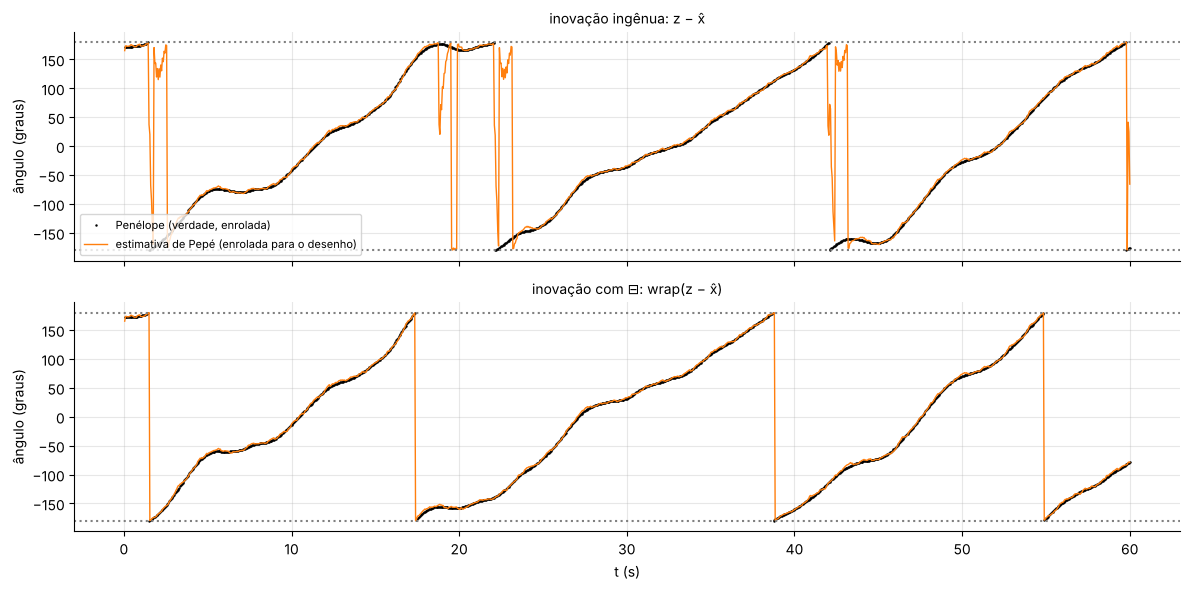

primeira passagem por ±180°: t = 1.45 s
OK   antes dela, os dois filtros dão a mesma estimativa:  diferença máxima = 0.00e+00


,perdeu o rastro,erro de ângulo (graus),erro de altura (cm),tempo com erro > 30°,desalinhamento de Pepé (graus),tempo com ela à vista,deslocamento de Penélope (voltas)
"teto, inovação ingênua",0 de 20,1.483511,12.096438,0.055,14.305185,0.872727,1.929777
"teto, inovação com ⊟",0 de 20,1.277319,12.096438,0.0,13.460404,0.929091,1.797818


In [5]:
cfg_ing = {"sensores": ["teto"], "inovacao_com_menos": False}
cfg_ok = {"sensores": ["teto"]}
fig, ax = plt.subplots(2, 1, figsize=(12, 6), sharex=True)
for a_, cfg, tit in zip(ax, [cfg_ing, cfg_ok], ["inovação ingênua: z − x̂", "inovação com ⊟: wrap(z − x̂)"]):
    h = simula(cfg, 100)
    a_.plot(h["t"], np.degrees(wrap(h["phi"])), "k.", ms=1.5, label="Penélope (verdade, enrolada)")
    a_.plot(h["t"], np.degrees(wrap(h["phi_h"])), color="tab:orange", lw=1, label="estimativa de Pepé (enrolada para o desenho)")
    a_.axhline(180, color="gray", ls=":"); a_.axhline(-180, color="gray", ls=":")
    a_.set_ylabel("ângulo (graus)"); a_.set_title(tit, fontsize=10)
    e = np.degrees(np.abs(wrap(h["phi"] - h["phi_h"])))
    print(f"{tit:32s}: erro máximo {e.max():6.1f}°;  tempo com erro > 30°: {100 * np.mean(e[100:] > 30):4.1f}%")
ax[0].legend(fontsize=8, loc="lower left"); ax[1].set_xlabel("t (s)"); plt.tight_layout(); plt.show()

# até a primeira passagem de Penélope por ±180°, as duas inovações são a mesma conta
h_i, h_o = simula(cfg_ing, 100), simula(cfg_ok, 100)
k_passa = np.argmax(np.abs(np.diff(wrap(h_i["phi"]))) > np.pi)
print(f"primeira passagem por ±180°: t = {h_i['t'][k_passa]:.2f} s")
confere("antes dela, os dois filtros dão a mesma estimativa", h_i["phi_h"][:k_passa - 5], h_o["phi_h"][:k_passa - 5], tol=1e-12)

tab_teto = monte_carlo({"teto, inovação ingênua": cfg_ing, "teto, inovação com ⊟": cfg_ok})
tab_teto.round(3)

**Leitura.**
- Na figura de cima, cada vez que Penélope passa por $\pm180°$, ou só chega perto (por volta de 19 s, ela não passa: é o **ruído da medida** que cruza a fronteira), a estimativa ingênua **dispara**: a inovação de quase $-360°$ puxa a estimativa para longe, com erro de até 161°, durante um ou dois segundos. Como as medidas seguintes continuam chegando, enroladas, o filtro acaba voltando, mas pelo caminho errado. Com o $\boxminus$ (embaixo), as passagens são invisíveis: o erro máximo é de uns 7°, e as linhas verticais são só o desenho do enrolamento. (A estimativa está desenhada enrolada; o filtro com $\boxminus$ a guarda sem enrolar, e ela acumula as voltas que Penélope dá.)
- No Monte Carlo, o filtro ingênuo nunca perde Penélope de vez, mas passa uns 5% do tempo com erro acima de 30°, contra zero com o $\boxminus$. O **erro mediano** quase não muda (1,5° contra 1,3°): a mediana esconde os episódios, que são curtos. É um defeito do tipo mais perigoso, que passa nos testes com estatísticas médias.
- Pepé, guiado pela estimativa ingênua, passa menos tempo com Penélope à vista (87% contra 93%).

---

## 4. O $\boxminus$ no controle

Uma implementação comum guarda o ângulo estimado **enrolado** (depois de cada correção, $\hat\varphi\leftarrow\mathrm{wrap}(\hat\varphi)$), para que ele não cresça sem limite. É uma boa prática, e o filtro continua certo, desde que a inovação use $\boxminus$. Mas agora o **ângulo de Pepé**, que ele acumula girando, e a estimativa vivem em "voltas" diferentes. Se o controle calcular o erro de giro com a subtração ingênua, $\hat\varphi-\theta$, uma estimativa que salta de $179°$ para $-179°$ manda Pepé girar quase uma volta inteira para o outro lado.

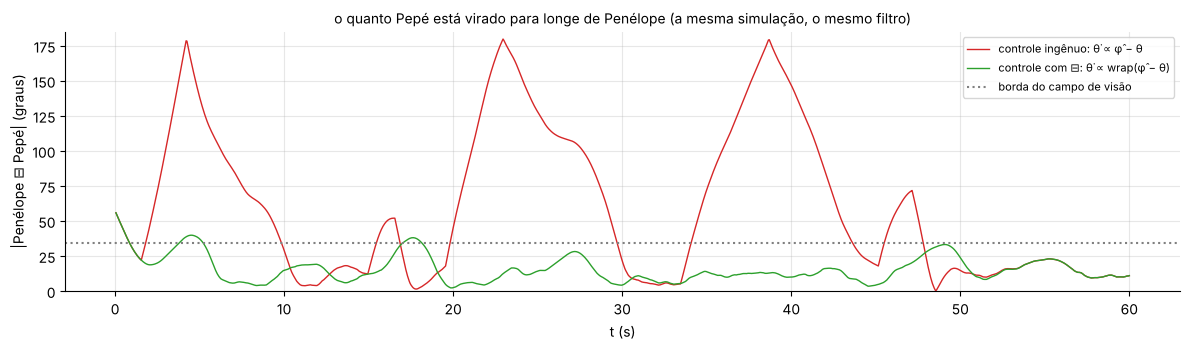

,perdeu o rastro,erro de ângulo (graus),erro de altura (cm),tempo com erro > 30°,desalinhamento de Pepé (graus),tempo com ela à vista,deslocamento de Penélope (voltas)
"teto ⊟, estado enrolado, controle ingênuo",0 de 20,1.317666,12.096438,0.0,25.915836,0.544545,0.974235
"teto ⊟, estado enrolado, controle com ⊟",0 de 20,1.277319,12.096438,0.0,13.460404,0.929091,1.797818


In [6]:
cfg_enrolado_ing = {"sensores": ["teto"], "estado_enrolado": True, "controle_com_menos": False}
cfg_enrolado_ok = {"sensores": ["teto"], "estado_enrolado": True}
h1, h2 = simula(cfg_enrolado_ing, 100), simula(cfg_enrolado_ok, 100)
fig, ax = plt.subplots(figsize=(12, 3.6))
ax.plot(h1["t"], np.degrees(np.abs(wrap(h1["phi"] - h1["th"]))), color="tab:red", lw=1, label="controle ingênuo: θ̇ ∝ φ̂ − θ")
ax.plot(h2["t"], np.degrees(np.abs(wrap(h2["phi"] - h2["th"]))), color="tab:green", lw=1, label="controle com ⊟: θ̇ ∝ wrap(φ̂ − θ)")
ax.axhline(np.degrees(FOV), color="gray", ls=":", label="borda do campo de visão")
ax.set_xlabel("t (s)"); ax.set_ylabel("|Penélope ⊟ Pepé| (graus)"); ax.legend(fontsize=8); ax.set_ylim(0, 185)
ax.set_title("o quanto Pepé está virado para longe de Penélope (a mesma simulação, o mesmo filtro)", fontsize=10)
plt.tight_layout(); plt.show()

tab_ctrl = monte_carlo({"teto ⊟, estado enrolado, controle ingênuo": cfg_enrolado_ing,
                        "teto ⊟, estado enrolado, controle com ⊟": cfg_enrolado_ok})
tab_ctrl.round(3)

**Leitura.** O filtro é o mesmo nas duas curvas, e acerta. Com o controle ingênuo, a cada vez que a estimativa enrolada salta de $+180°$ para $-180°$, Pepé gira pelo caminho longo: fica de costas para Penélope (desalinhamento de até 180°) e leva de seis a dez segundos para voltar a vê-la. No Monte Carlo, o tempo com ela à vista cai de 93% para 54%, e o desalinhamento mediano quase dobra (de 13° para 26°). O erro de **estimativa** continua o mesmo: o defeito está no controle, não no filtro.

---

## 5. Os olhos de Pepé: EKF com jacobianos por números duais

Agora Pepé usa os próprios olhos. A medida é não linear, e o EKF lineariza $h$ em torno da estimativa com o jacobiano dual da seção 2. Dois cuidados, ambos com o $\boxminus$:
- a medida depende de $\varphi-\theta$; antes de linearizar, a estimativa é escrita **vista de Pepé**, $\theta\boxplus(\hat\varphi\boxminus\theta)$, para que a diferença esteja em $(-\pi,\pi]$;
- se a estimativa está muito longe do centro da imagem (mais de 1,2 rad), a tangente já não serve para linearizar, e a medida é descartada.

Três configurações: só os olhos; os olhos com a câmera do teto **uma vez por segundo** (para reencontrar Penélope se ela escapar do campo de visão); e, para comparar, só a câmera do teto a 1 Hz.

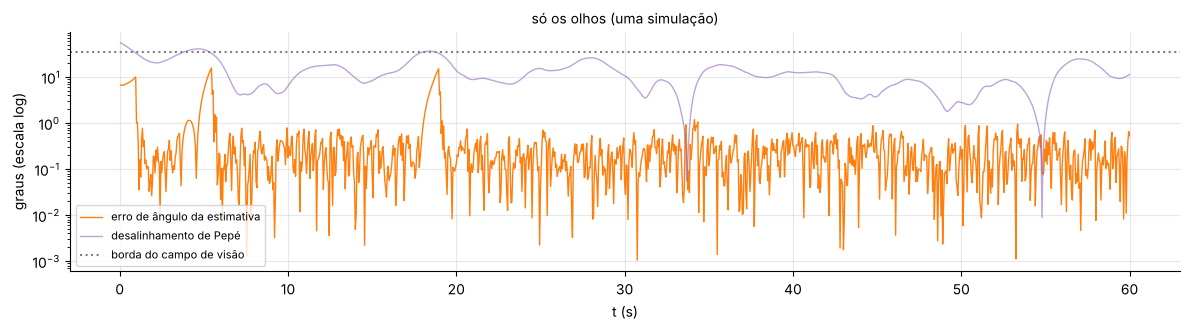

,perdeu o rastro,erro de ângulo (graus),erro de altura (cm),tempo com erro > 30°,desalinhamento de Pepé (graus),tempo com ela à vista,deslocamento de Penélope (voltas)
"olhos (EKF, jacobiano dual)",0 de 20,0.223606,1.958034,0.045455,14.245133,0.917273,1.461829
olhos + teto a 1 Hz,0 de 20,0.206443,1.926974,0.0,12.745883,0.933182,1.721013
só teto a 1 Hz,0 de 20,3.890698,32.951187,0.000455,14.874263,0.885,1.449638


In [7]:
tab_olhos = monte_carlo({"olhos (EKF, jacobiano dual)": {"sensores": ["olhos"]},
                         "olhos + teto a 1 Hz": {"sensores": ["olhos", "teto"], "teto_hz": 1},
                         "só teto a 1 Hz": {"sensores": ["teto"], "teto_hz": 1}})
h = simula({"sensores": ["olhos"]}, 100)
fig, ax = plt.subplots(figsize=(12, 3.4))
ax.semilogy(h["t"], np.degrees(np.abs(wrap(h["phi"] - h["phi_h"]))) + 1e-3, color="tab:orange", lw=1, label="erro de ângulo da estimativa")
ax.semilogy(h["t"], np.degrees(np.abs(wrap(h["phi"] - h["th"]))) + 1e-3, color="tab:purple", lw=1, alpha=.6, label="desalinhamento de Pepé")
ax.axhline(np.degrees(FOV), color="gray", ls=":", label="borda do campo de visão")
ax.set_xlabel("t (s)"); ax.set_ylabel("graus (escala log)"); ax.legend(fontsize=8); ax.set_title("só os olhos (uma simulação)", fontsize=10)
plt.tight_layout(); plt.show()
tab_olhos.round(3)

**Leitura.**
- **Os olhos sozinhos** estimam o ângulo com erro mediano de 0,22°, seis vezes menos que a câmera do teto a 10 Hz, e a altura com 2 cm, contra 12 cm. O jacobiano dual funcionou como o jacobiano à mão funcionaria (a conferência da seção 2 diz que são iguais).
- Mas os olhos só veem o que está à frente. Na figura, por volta de 5 s e de 18 s, Penélope escapa da borda do campo de visão (ela foge quando é encarada); sem medidas, o filtro só prediz, e o erro sobe para 10° ou 20°, até que ela volte a ficar à vista. No Monte Carlo, isso ocupa uns 4,5% do tempo (mediana).
- **Olhos e câmera do teto a 1 Hz:** a mesma precisão dos olhos, e nenhum instante com erro acima de 30°. A câmera do teto, sozinha a 1 Hz, erra quase 4° e 33 cm; como reserva dos olhos, basta.

---

## 6. Tudo junto

In [8]:
pd.concat([tab_teto, tab_ctrl, tab_olhos]).round(3)

,perdeu o rastro,erro de ângulo (graus),erro de altura (cm),tempo com erro > 30°,desalinhamento de Pepé (graus),tempo com ela à vista,deslocamento de Penélope (voltas)
"teto, inovação ingênua",0 de 20,1.483511,12.096438,0.055,14.305185,0.872727,1.929777
"teto, inovação com ⊟",0 de 20,1.277319,12.096438,0.0,13.460404,0.929091,1.797818
"teto ⊟, estado enrolado, controle ingênuo",0 de 20,1.317666,12.096438,0.0,25.915836,0.544545,0.974235
"teto ⊟, estado enrolado, controle com ⊟",0 de 20,1.277319,12.096438,0.0,13.460404,0.929091,1.797818
"olhos (EKF, jacobiano dual)",0 de 20,0.223606,1.958034,0.045455,14.245133,0.917273,1.461829
olhos + teto a 1 Hz,0 de 20,0.206443,1.926974,0.0,12.745883,0.933182,1.721013
só teto a 1 Hz,0 de 20,3.890698,32.951187,0.000455,14.874263,0.885,1.449638


**Leitura.** Nenhuma configuração perdeu Penélope de vez: este domínio não tem a ambiguidade dos sensores de cheiro dos domínios I e II, e todos os sensores informam o lado e a altura. O que separa as configurações são os **detalhes de implementação do círculo** ($\boxminus$ na inovação, $\boxminus$ no controle) e a **combinação de sensores** (os olhos precisos com o teto como reserva). A coluna do deslocamento de Penélope mostra que, em 60 s, ela anda em mediana uma volta e meia a duas voltas em torno do silo: as passagens por $\pm180°$ não são raras.

---

## 7. O que levar deste notebook

1. **Um ângulo não é um número.** Toda diferença entre ângulos, seja a inovação do filtro, seja o erro do controle, se calcula com $\boxminus$. Toda soma de um incremento a um ângulo, com $\boxplus$. São duas linhas de código, e a falta de qualquer uma delas produz erros que só aparecem quando o alvo passa por $\pm180°$, isto é, raramente, de surpresa e no pior momento.
2. **O mesmo erro tem sintomas diferentes em lugares diferentes.** Sem $\boxminus$ na inovação, o filtro erra por alguns segundos e se recupera; sem $\boxminus$ no controle, o filtro está certo e Pepé é que se perde.
3. **Jacobianos por números duais tiram a dedução do caminho.** Os olhos de Pepé têm um modelo com tangentes e quocientes; o EKF usou o jacobiano exato sem uma linha de derivada escrita à mão. Para mudar o sensor, basta mudar `h_olhos`.
4. **Sensores precisos e estreitos combinam com sensores grosseiros e largos.** Os olhos dão precisão; a câmera do teto, mesmo a 1 Hz, dá a garantia de reencontrar Penélope.

**Próximo domínio:** os números complexos ([nó do domínio IV](X4_complexos.ipynb) ([Colab](https://colab.research.google.com/github/saulobortolon/Quaternios-Kalman-CC/blob/main/dominios/notebooks/X4_complexos.ipynb))). A rotação deixa de ser um ângulo que se enrola e passa a ser um **número** de módulo 1, $e^{i\theta}$, que se compõe por multiplicação: o enrolamento desaparece da álgebra, porque $e^{i(\theta+2\pi)}=e^{i\theta}$ automaticamente.

---

## 8. Exercícios

1. **Onde está o enrolamento?** Na configuração "teto, inovação ingênua", conte quantas vezes Penélope passa por $\pm180°$ em cada simulação e compare com o número de episódios de erro acima de 30°. Os dois números batem?
2. **Média de estimativas.** Rode dois filtros (um com a câmera do teto, outro com os olhos) e combine as estimativas de ângulo pela média ponderada pelas variâncias. Faça a média ingênua e a média circular (notebook III(a), seção 5). Em que situação elas diferem?
3. **IEKF nos olhos.** Implemente a correção iterada (notebook I(d)) para os olhos. Ela muda alguma coisa quando Penélope está perto da borda do campo de visão, onde a tangente é mais curva?
4. **Ângulo absoluto nos olhos.** Suponha que os olhos de Pepé medem $\Delta$ diretamente (um sensor de direção), e não $\tan\Delta$. O jacobiano fica trivial. O filtro melhora ou piora? Por quê?
5. **Penélope que dá voltas.** Aumente a força aleatória horizontal para 4 N, para que Penélope dê mais voltas. Como mudam as diferenças entre a inovação ingênua e a com $\boxminus$?